In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("Advertising.csv")
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [4]:
df.shape

(200, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [6]:
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [7]:
df.isnull().sum()

Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

ValueError: Could not interpret value `Sales` for `y`. An entry with this name does not appear in `data`.

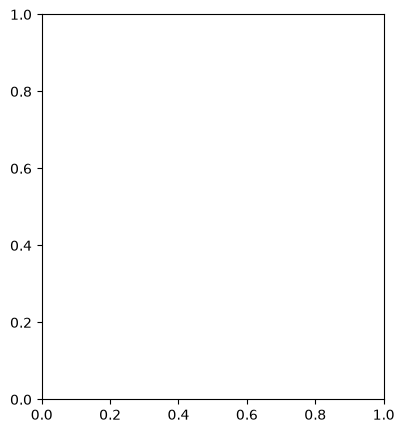

In [8]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x='TV', y='Sales', data=df)
plt.title('TV Advertising vs Sales')

plt.subplot(1, 3, 2)
sns.scatterplot(x='Radio', y='Sales', data=df)
plt.title('Radio Advertising vs Sales')

plt.subplot(1, 3, 3)
sns.scatterplot(x='Newspaper', y='Sales', data=df)
plt.title('Newspaper Advertising vs Sales')

plt.tight_layout()
plt.show()

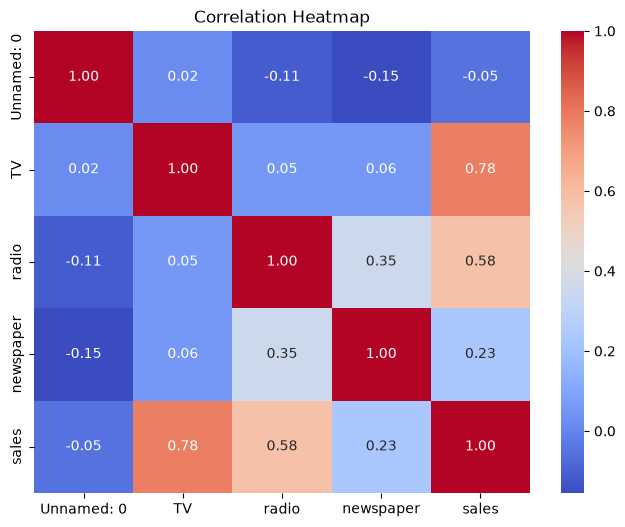

In [9]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [11]:
print(df.columns.tolist())

['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']


In [12]:
df.head()


,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [13]:
print(df.columns.tolist())

['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']


In [14]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']


In [15]:
print(df.head())
print(df.columns.tolist())

   Unnamed: 0     TV  radio  newspaper  sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9
['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']


In [23]:
df = pd.read_csv("Advertising.csv", index_col=0)

df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['tv', 'radio', 'newspaper', 'sales']


In [18]:
print("Column names:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)

Column names: ['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales']

First 5 rows:


,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9



Dataset shape: (200, 5)


In [24]:
X = df[['tv', 'radio', 'newspaper']]
y = df['sales']

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (200, 3)
Dependent Variable Shape: (200,)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (160, 3)
Testing Data: (40, 3)
Training Target: (160,)
Testing Target: (40,)


In [26]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [27]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [0.04472952 0.18919505 0.00276111]
Intercept: 2.979067338122629


In [28]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)

Predicted Values:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967  9.04831992  6.65328312
 14.34554487  8.90349333  9.68959028 12.16494386  8.73628397 16.26507258
 10.27759582 18.83109103 19.56036653 13.25103464 12.33620695 21.30695132
  7.82740305  5.80957448 20.75753231 11.98138077  9.18349576  8.5066991
 12.46646769 10.00337695 21.3876709  12.24966368 18.26661538 20.13766267
 14.05514005 20.85411186 11.0174441   4.56899622]

Actual Values:
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 11.5 14.9  9.5  8.7 11.9  5.3
 10.3 11.7  5.5 16.6 11.3 18.9 19.7 12.5 10.9 22.2  9.3  8.1 21.7 13.4
 10.6  5.7 10.6 11.3 23.7  8.7 16.1 20.7 11.6 20.8 11.9  6.9]


In [29]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 1.4607567168117603
Mean Squared Error: 3.1740973539761033
Root Mean Squared Error: 1.78159966153345
R2 Score: 0.899438024100912


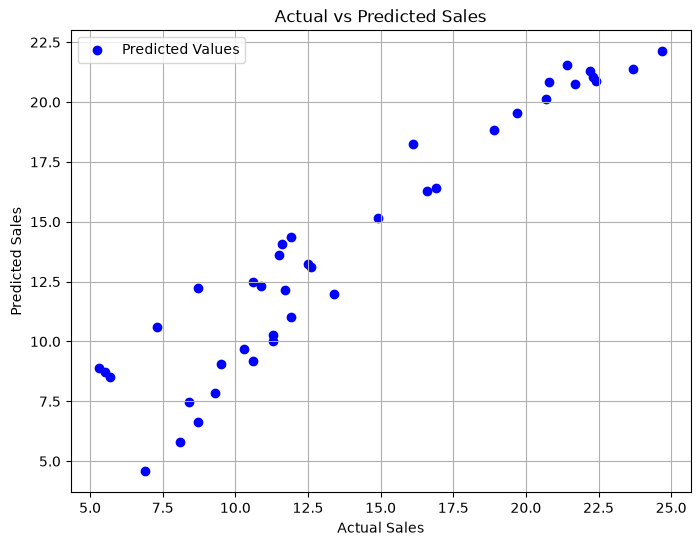

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, color='blue', label='Predicted Values')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.grid(True)

plt.show()


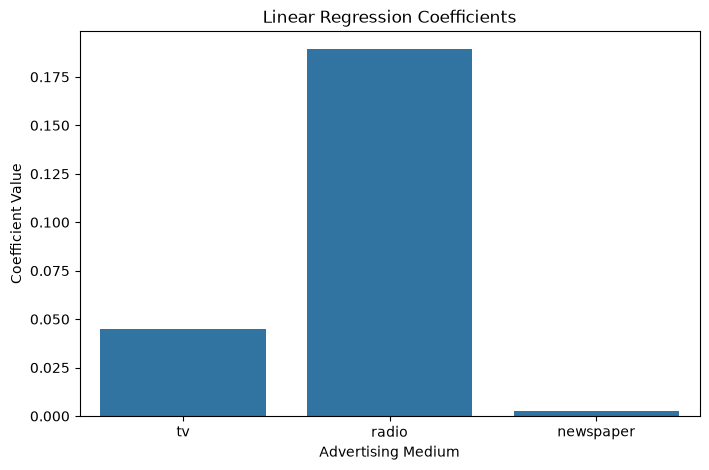

In [31]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

plt.figure(figsize=(8, 5))

sns.barplot(data=coefficients, x='Feature', y='Coefficient')

plt.title('Linear Regression Coefficients')
plt.xlabel('Advertising Medium')
plt.ylabel('Coefficient Value')

plt.show()

In [32]:
new_data = pd.DataFrame({
    'tv': [200],
    'radio': [40],
    'newspaper': [30]
})

predicted_sales = model.predict(new_data)

print("New Advertising Data:")
display(new_data)

print("Predicted Sales:", predicted_sales[0])

New Advertising Data:


,tv,radio,newspaper
0,200,40,30


Predicted Sales: 19.575606431481972
